In [3]:
import glob
from skimage import io, transform
from corebreakout.utils.viz_utils import show_images

In [5]:
img_path = '/home/administrator/Dropbox/core_data/segmentation/royal_fullsize_images/'
masks_path = '/home/administrator/Dropbox/core_data/segmentation/royal_fullsize_masks/'

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/transform/_warps.py:84: UserWarning: The default mode, 'constant', will be changed to 'reflect' in skimage 0.15.
  warn("The default mode, 'constant', will be changed to 'reflect' in "


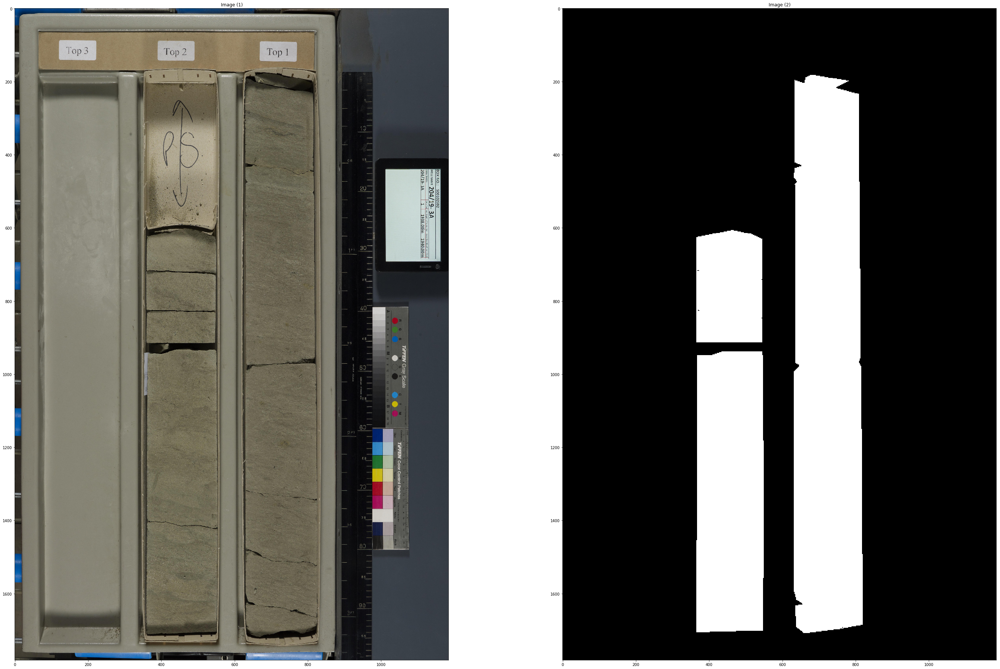

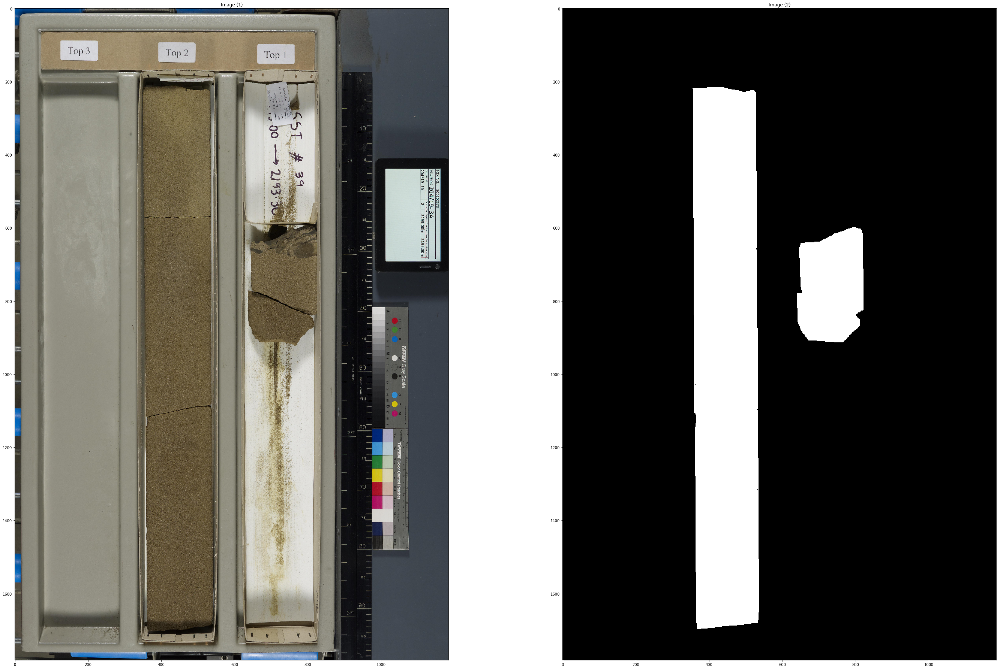

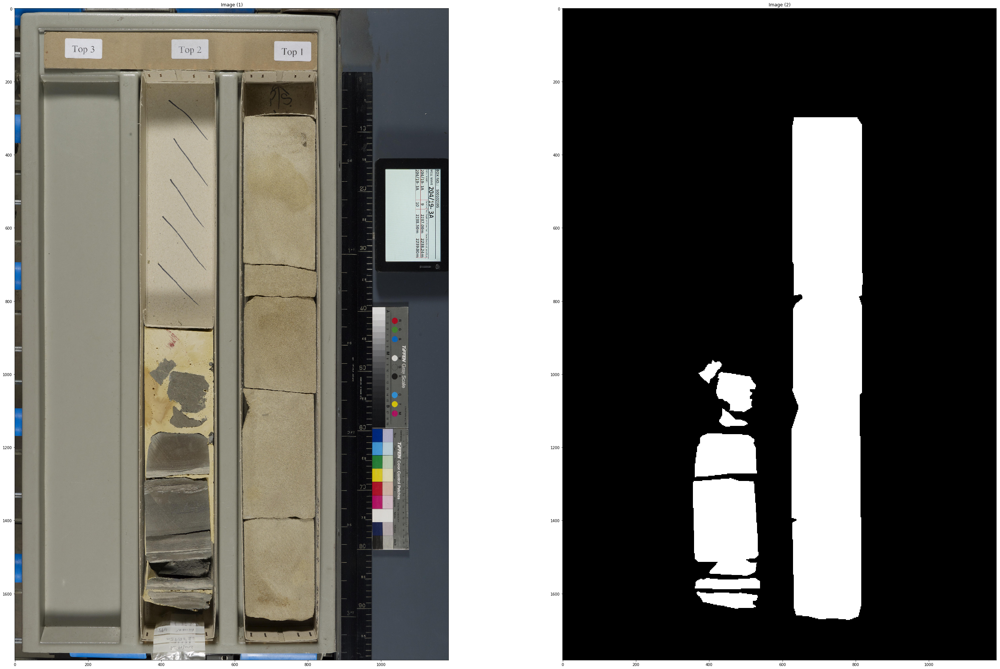

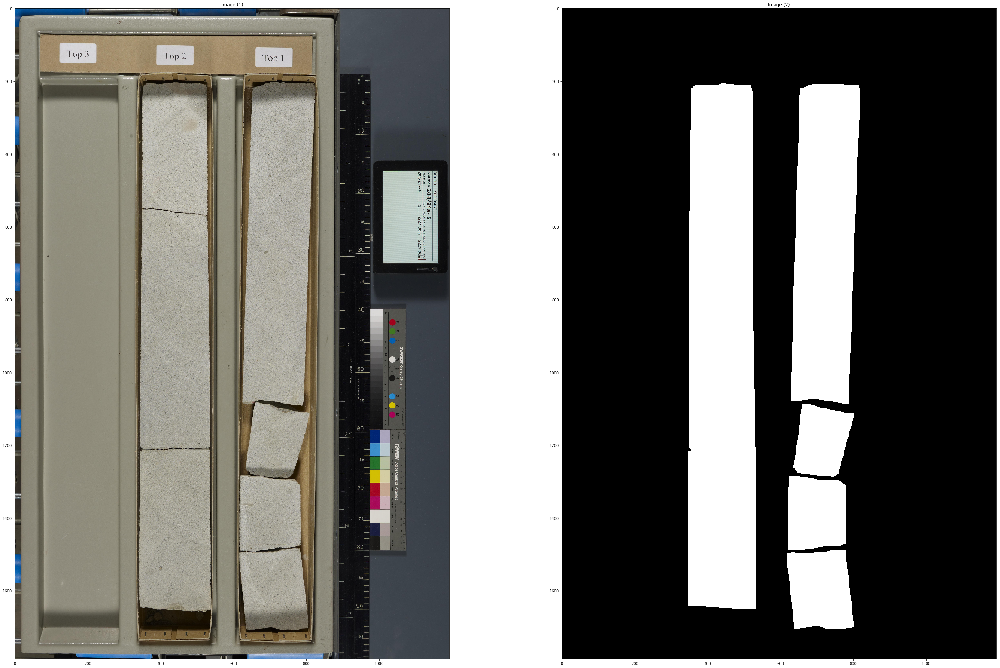

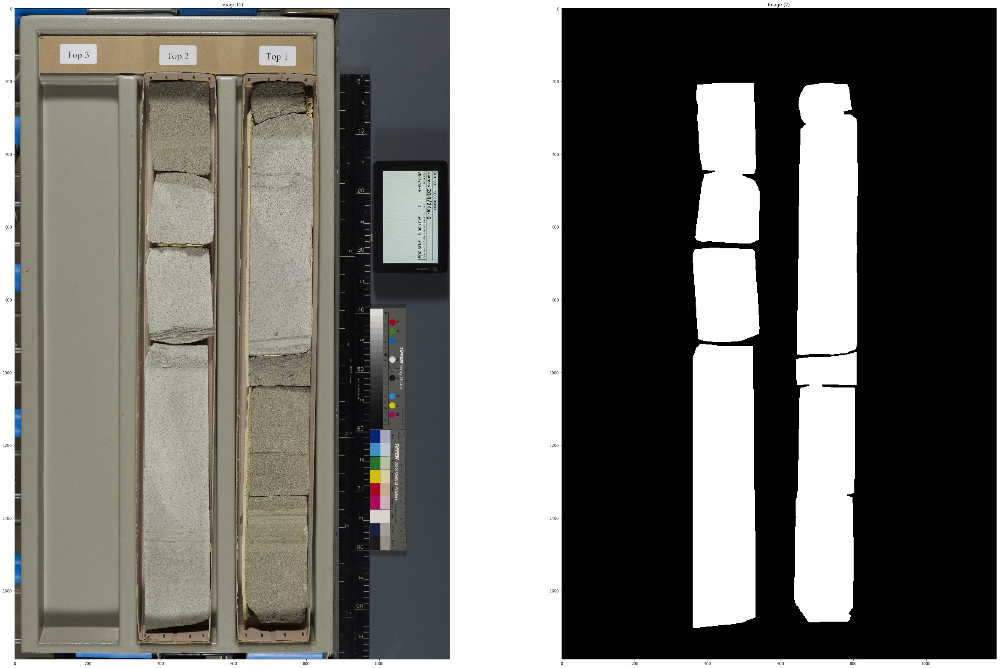

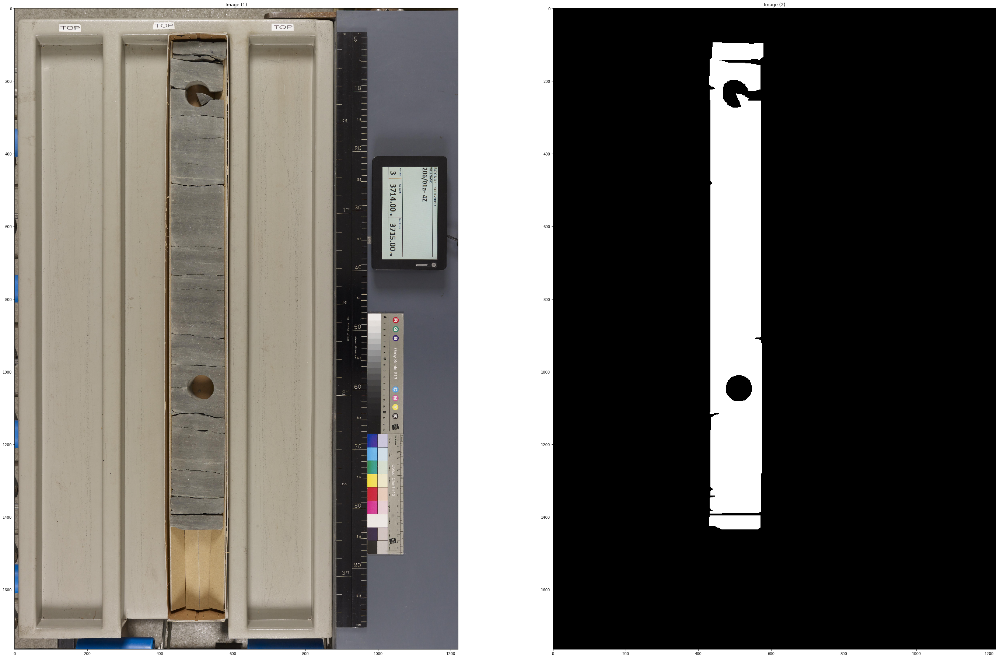

In [9]:
# going to downsize them first -- more practical, no memory problems with U-Net
ifiles = sorted(glob.glob(img_path+'*.jpeg'))
mfiles = sorted(glob.glob(masks_path+"*.jpeg"))

imgs = [io.imread(f) for f in ifiles]
masks = [io.imread(f) for f in mfiles]

s_imgs = [transform.rescale(img, 0.25) for img in imgs]
s_masks = [(transform.rescale(m, 0.25)>0) for m in masks]

for img, mask in zip(s_imgs, s_masks):
    show_images([img, mask])

In [12]:
isave_dir = '/home/administrator/Dropbox/core_data/segmentation/royal_smaller_images/'
msave_dir = '/home/administrator/Dropbox/core_data/segmentation/royal_smaller_masks/'

names = [s.split('/')[-1] for s in ifiles]

# need to write them out for augmentor to read them back in
for name, img, mask in zip(names, s_imgs, s_masks):
    io.imsave(isave_dir+name, img)
    io.imsave(msave_dir+name, mask)

/home/administrator/anaconda3/envs/core-dev/lib/python3.6/site-packages/skimage/util/dtype.py:122: UserWarning: Possible precision loss when converting from float64 to uint8
  .format(dtypeobj_in, dtypeobj_out))
